# Dispersion géographique des adhérents d'un club

In [ ]:
import numpy as np
import pandas as pd
import re
import os
import CTG_Utils as ctg


def built_lat_long(df,ville_ref):
    
    # Standard library imports
    from collections import Counter
    from pathlib import Path
    
    # 3rd party imports
    import folium
    import numpy as np
    import pandas as pd
    
    path_villes_de_france = Path(r'C:\Users\franc\CTG\DATA\FICHIERS REFERENCES') / Path('villes_france_premium.csv')
    
    def normalize_ville(x):
        dic_ville = {'SAINT-HILAIRE-DU-TOUVET':"SAINT-HILAIRE-38",
                     'SAINT-HILAIRE':"SAINT-HILAIRE-38",
                     'LAVAL-EN-BELLEDONNE':'LAVAL-38',
                     'LAVAL':"LAVAL-38",
                     'CRETS-EN-BELLEDONNE':"SAINT-PIERRE-D'ALLEVARD",
                     'LA SURE-EN-CHARTREUSE': 'SAINT-JULIEN-DE-RAZ',
                     'AUTRANS-MEAUDRE-EN-VERCORS':'AUTRANS',
                     'VOIRO?':'VOIRON',
                     'TULLINS-FURES':'TULLINS',
                     'LES-ABRETS-EN-DAUPHINE':'LES ABRETS',
                     'MONTFERRAT':'MONTFERRAT-38',
                     'RIVES':'RIVES-38',
                     'SAINT-VALLIER':'SAINT-VALLIER-26',
                     "SAINT-VERAND":"SAINT-VERAND-38",
                     'SAINT-JUSAINT-DE-CLAIX':"SAINT-JUST-DE-CLAIX",
                     "SAINT-SAUVEUR":"SAINT-SAUVEUR-38",
                     "CHEVRIERES":"CHEVRIERES-38",
                     "BEAULIEU":"BEAULIEU-38",
                     "CHASSELAY":"CHASSELAY-38"}
        if x in dic_ville.keys(): 
            return dic_ville[x]
        else:
            return x
        
    def compute_dist(row):
        return  _distance(lat_ref, long_ref, row['lat'], row['long']) 
        
    df_villes = pd.read_csv(path_villes_de_france,header=None,usecols=[3,19,20])
    dic_long = dict(zip(df_villes[3] , df_villes[19]))
    dic_lat = dict(zip(df_villes[3] , df_villes[20]))

    df['Ville'] = df['Ville'].str.replace(' ','-')
    df['Ville'] = df['Ville'].str.replace('ST-','SAINT-')
    df['Ville'] = df['Ville'].str.replace('\-D\-+',"-D'",regex=True)
    df['Ville'] = df['Ville'].str.replace('^LA-',"LA ",regex=True)
    df['Ville'] = df['Ville'].str.replace('^LE-',"LE ",regex=True)
    
    df['Ville'] = df['Ville'].apply(normalize_ville)
    

    df['long'] = df['Ville'].map(dic_long)
    df['lat'] = df['Ville'].map(dic_lat)
    print(ville_ref)
    long_ref, lat_ref =  dic_long[ville_ref], dic_lat[ville_ref]
    df['distance'] = df.apply(compute_dist,axis=1)
    return df

def _distance(ϕ1, λ1,ϕ2, λ2):
    from math import asin, cos, radians, sin, sqrt
    ϕ1, λ1 = radians(ϕ1), radians(λ1)
    ϕ2, λ2 = radians(ϕ2), radians(λ2)
    rad = 6371
    dist = 2 * rad * asin(
                            sqrt(
                                sin((ϕ2 - ϕ1) / 2) ** 2
                                + cos(ϕ1) * cos(ϕ2) * sin((λ2 - λ1) / 2) ** 2
                            ))
    return dist

ville = 'BERNIN' #'CTG'#'SAINT-ROMANS' #'COUBLEVIE' # 
root_path = r'C:\Users\franc\CTG\DATA\FICHIERS EXCEL\clubs 38'

if ville != 'CTG':
    file = os.path.join(root_path, ville+'.xlsx')

    df = pd.read_excel(file,
                      header= None)
    df.columns = ['adresse']
    df['Ville'] =df['adresse'].apply(lambda x: re.findall(r'\d{5}.*',x)[0][6:])
    df = built_lat_long(df,ville)
else:
    df = ctg.read_effectif(2023)
    df = df[['Ville','distance','long']]

dg = df.groupby(['Ville']).count()['long']
dg = pd.DataFrame({'ville':dg.index, '# adhérents':dg.values})
dg.to_excel(os.path.join(root_path, ville+'_results.xlsx'))

distance_moyenne = np.mean(np.array(df['distance'].tolist()))
distance_mediane = np.median(np.array(df['distance'].tolist()))
print(f'{ville} # adhérents : {len(df)} rayon moyen : {distance_moyenne} \
: rayon médian {distance_mediane} nombre de ville {len(dg)}')

# CALENDRIER RANDONNEES COPEP 38

In [ ]:
from datetime import date
import datetime
import calendar
import re
from collections import defaultdict
from textwrap import wrap
import unicodedata

import os
from pathlib import Path

import pandas as pd
import xlrd

from docxtpl import DocxTemplate
from docxcompose.composer import Composer
from docx import Document as Document_compose



VERSION = '04'
semi_quadratin = "\u2014"
JOURS_DIC = {"Monday" :"lundi",
             "Tuesday" :"mardi",
             "Wednesday" :"mercredi",
             "Thursday" :"jeudi",
             "Friday" :"vendredi",
             "Saturday" :"samedi",
             "Sunday" :"dimanche",}

MONTHS_DIC = {"janvier" : 1,
              "février" : 2,
              "mars" : 3,
              "avril" : 4,
              "mai" : 5,
              "juin" : 6,
              "juillet" : 7,
              "août" : 8,
              "septembre" : 9,
              "octobre" : 10,
              "novembre" : 11,
              "décembre" : 12,}

templates_dict = {'Route': 'template_randonnees_route.docx',
                  'Route/ Gravel': 'template_randonnees_route_gravel.docx',
                  'Route/ Pédestre': 'template_randonnees_route_pedestre.docx',
                  'Route/ Vtt': 'template_randonnees_route_vtt.docx',
                  'Route/ Vtt/ Gravel': 'template_randonnees_route_vtt_gravel.docx',
                  'Route/ Vtt/ Pédestre': 'template_randonnees_route_vtt_pedestre.docx',
                  "BOURSE AUX VELOS": 'template_randonnees_bourse_aux_velos.docx',
                  'Vtt/ Pédestre': 'template_randonnees_vtt_pedestre.docx',
                  'Vtt':'template_randonnees_vtt.docx',
                  'Vtt/ Gravel':'template_randonnees_vtt_gravel.docx',
                  'Route/ Vtt/ Pédestre/ Gravel': 'template_randonnees_route_vtt_pedestre_gravel.docx'}

year = 2026
#root = Path.home() / Path('CODEP38')  / Path(str(year)) / Path('randonnees') 

root = Path(r"C:\Users\franc\CODEP38") / Path(str(2026)) / Path('randonnees') 
#PATH_TEMPLATES = Path.home() / Path('CODEP38/TEMPLATES')

PATH_TEMPLATES = Path(r"C:\Users\franc\Dropbox\Codep 38\Année 2026\Calendrier\TEMPLATES")
PATH_OUTPUT = Path.home() / Path('CODEP38') / Path(str(year)) / Path('Calendrier')

def make_table_matiere(df):

    output_file = PATH_OUTPUT / Path( 'liste_matiere.docx')
    
    frameworks = []
    for idx,row in df.iterrows():
        frameworks.append(dict(mois = row['date'].split(' ')[1] + ' ' + row['mois'],
                               typ = row['Type de manifestation'],
                               name = row['nom_randonnee'],))
                
    context ={'year': year,
              'frameworks': frameworks}
    template_docx = PATH_TEMPLATES  / Path('template_Liste_matiere.docx')
    doc = DocxTemplate(template_docx) 
    doc.render(context)
    doc.save(output_file)
    
def concat_tel(row):
    if len(row["tel_fixe"]) > 0:
        return row["tel_fixe"] + " / " + row["tel_mobile"]
    else:
        return row["tel_mobile"]

def has_numbers(inputString):
    return any(char.isdigit() for char in inputString)

def normalize_euro(text):

    rep = {"euros": "€", "euro": "€", "Euros":"€","Euro":"€"} 
    pattern = re.compile("|".join(rep.keys()))
    text = pattern.sub(lambda m: rep[re.escape(m.group(0))], text)
    return text

def combine_all_docx(list_docx,year):

    """
    Merges all the docx file contained in `list_docx` 
    """

    filename_master = PATH_TEMPLATES / Path('premiere-de-couverture.docx')
    number_of_sections = len(list_docx)
    master = Document_compose(filename_master)
    composer = Composer(master)
    for i in range(0, number_of_sections):
        doc_temp = Document_compose(list_docx[i])
        try:
            composer.append(doc_temp)
        except:
            pass
            
    file_name = f'CALENDRIER_{str(year)}.docx'
    combine_file = PATH_OUTPUT / file_name
    print(combine_file)
    composer.save(combine_file)

def builds_organisation_docx(df,year):
    
    long = 1  # for future use
    file_list = []
    list_docx = []
    idx = 0
    for i_dep in range(0,len(df),long):
        i_fin = i_dep+long
        template_path_docx = df['template'].tolist()[i_dep:i_fin][0]
        template_path_docx = PATH_TEMPLATES / Path(template_path_docx)
        doc = DocxTemplate( template_path_docx)
        
        f ={'version': VERSION,
            'mois': df['mois'].tolist()[i_dep:i_fin],
            'jour': df['date'].tolist()[i_dep:i_fin],
            'titre1': df['nom_randonnee'].tolist()[i_dep:i_dep+long],
            'titre2': df['club_organisateur'].tolist()[i_dep:i_fin],
            'type': df['Type de manifestation'].tolist()[i_dep:i_fin],
            'lieu1': df['adresse1'].tolist()[i_dep:i_fin],
            'lieu2': df['adresse2'].tolist()[i_dep:i_fin],
            'horaire': df['horaire'].tolist()[i_dep:i_fin],
            'kr': df['distances_routes'].tolist()[i_dep:i_fin],
            'kv': df['distances_vtt'].tolist()[i_dep:i_fin],
            'kp': df['distances_pedestre'].tolist()[i_dep:i_fin],
            'kg':  df['distances_gravel'].tolist()[i_dep:i_fin],
            'tffct': df['tarifs_ffct_route'].tolist()[i_dep:i_fin],
            'tffct_18': df['tarifs_ffct_route_18'].tolist()[i_dep:i_fin],
            'aut': df['tarifs_non_ffct_route'].tolist()[i_dep:i_fin],
            'aut_18': df['tarifs_non_ffct_route_18'].tolist()[i_dep:i_fin],
            'tp': df['tarifs_pedestre'].tolist()[i_dep:i_fin],
            'tp_18': df['tarifs_pedestre_18'].tolist()[i_dep:i_fin],
            'nom': df['contact'].tolist()[i_dep:i_fin],
            'tel': df['tel_mobile'].tolist()[i_dep:i_fin],
            'mail': df['courriel'].tolist()[i_dep:i_fin],
            'web': df['web'].tolist()[i_dep:i_fin]}
            
            
        doc.render(f)
        #    
        output_file = PATH_OUTPUT / Path("5-sejour"+str(idx)+".docx")
        doc.save(output_file)
        list_docx.append(output_file)
    
        idx += 1
        
    return list_docx
       

def normalize_time(s):
    l = re.split(r"[\D]+", str(s).strip())
    minutes = l[1].zfill(2) if len(l) ==2 else '00'
    t = l[0].zfill(2)+ " h " + minutes
    return t

def dic_rando(year,root):
    
    YEAR = year
    jours = ['lundi','mardi','mercredi','jeudi','vendredi','samedi','dimanche']
    
    
    def normalize_num_tel(s):
        if isinstance(s,float) : s = int(s)
        s = str(s)
        if len(s)>0:
            digits = ''.join(char for char in s if char.isdigit())
            digits = digits.zfill(10)
            return " ".join(wrap(digits, width=2))
        else:
            return ''
        
    def parse_date(worksheet,workbook,num_row):
        my_date = worksheet.cell_value(num_row,1)
        
    
        if isinstance(my_date,float):
            my_date = datetime.datetime(*xlrd.xldate_as_tuple(my_date, workbook.datemode))
            my_date = my_date.replace(year=year)
        else:   
            my_date_split = my_date.split()
            if my_date_split[0].lower() in jours:
                my_date = datetime.datetime(YEAR,MONTHS_DIC[my_date_split[2].lower()], int(my_date_split[1]))
            elif "/" in my_date:
                my_date_split = my_date.split('/')
                my_date = datetime.datetime(YEAR,int(my_date_split[1]), int(my_date_split[0]))
            elif "," in my_date:
                my_date_split = my_date.split(',')
                my_date = datetime.datetime(YEAR,int(my_date_split[1]), int(my_date_split[0]))    
            elif str(YEAR) in my_date:
                print(file,my_date)
                my_date = datetime.datetime(YEAR,int(my_date_split[1]), int(my_date_split[0]))
            else:
                print(f'Cannot parse date in file : {file}')
                my_date = datetime.datetime(YEAR,1, 1)
        return my_date
        
    def parse_nom_randonnee(worksheet,num_row):
        return worksheet.cell_value(num_row,4).strip().upper()
    
    def parse_club_organisateur(worksheet,num_row):
        return worksheet.cell_value(num_row,4).strip()
    
    def parse_numero_federal(worksheet,num_row):
        numero_federal = worksheet.cell_value(num_row,23)
        if numero_federal:
            return str(int(numero_federal)).zfill(5)
        else:
            return ''
    
    def parse_adresse_1(worksheet,num_row):
        return worksheet.cell_value(num_row,3)

    def parse_adresse_2(worksheet,num_row):
        return worksheet.cell_value(num_row,3)
    
    def parse_horaire_ouverture_deb(worksheet,workbook,num_row):
        cell_type = worksheet.cell_type(num_row,4)
        cell_value = worksheet.cell_value(num_row,4)
        if cell_type == xlrd.XL_CELL_DATE:
            dt_tuple = xlrd.xldate_as_tuple(cell_value, workbook.datemode)
            t = str(dt_tuple[3]).zfill(2) + ' h ' + str(dt_tuple[4]).zfill(2)
            return t
        else:
            return normalize_time(worksheet.cell_value(num_row,4))
            
    def parse_horaire_ouverture_fin(worksheet,workbook,num_row):
        cell_type = worksheet.cell_type(num_row,6)
        cell_value = worksheet.cell_value(num_row,6)
        if cell_type == xlrd.XL_CELL_DATE:
            dt_tuple = xlrd.xldate_as_tuple(cell_value, workbook.datemode)
            t = str(dt_tuple[3]).zfill(2)+ ' h ' + str(dt_tuple[4]).zfill(2)
            return t
        else:
            return normalize_time(worksheet.cell_value(num_row,6))  
            
    def parse_horaire_fermeture(worksheet,workbook,num_row):
        cell_type = worksheet.cell_type(num_row,4)
        cell_value = worksheet.cell_value(num_row,4)
        if cell_type == xlrd.XL_CELL_DATE:
            dt_tuple = xlrd.xldate_as_tuple(cell_value, workbook.datemode)
            t = str(dt_tuple[3]).zfill(2)+ ' h ' + str(dt_tuple[4]).zfill(2)
            return t
        else:
            return normalize_time(worksheet.cell_value(num_row,4))

    def parse_distance_route(worksheet,num_row):
        lst = [str(int(x)) for x in [worksheet.cell_value(num_row,5),
                worksheet.cell_value(num_row,6),
                worksheet.cell_value(num_row,7),
                worksheet.cell_value(num_row,8),
                worksheet.cell_value(num_row,9),
                worksheet.cell_value(num_row,10),
                worksheet.cell_value(num_row,11),
                worksheet.cell_value(num_row,12)] if isinstance(x,float)]
        lst.sort()
        distance_route = ', '.join(lst)
        return distance_route
        
    def parse_distance_vtt(worksheet, num_row):
        lst = [str(int(x)) for x in [worksheet.cell_value(num_row,5),
                worksheet.cell_value(num_row,6),
                worksheet.cell_value(num_row,7),
                worksheet.cell_value(num_row,8),
                worksheet.cell_value(num_row,9),
                worksheet.cell_value(num_row,10),
                worksheet.cell_value(num_row,11),
                worksheet.cell_value(num_row,12)] if isinstance(x,float)]
        lst.sort()
        distance_vtt = ', '.join(lst)
        return distance_vtt
        
    def parse_distance_pedestre(worksheet, num_row):
        lst = [str(int(x)) for x in [worksheet.cell_value(num_row,5),
                worksheet.cell_value(num_row,6),
                worksheet.cell_value(num_row,7),
                worksheet.cell_value(num_row,8),
                worksheet.cell_value(num_row,9),
                worksheet.cell_value(num_row,10),
                worksheet.cell_value(num_row,11),
                worksheet.cell_value(num_row,12)] if isinstance(x,float)]
        lst.sort()
        distance_pedestre =  ', ' .join(lst)
        return distance_pedestre

    def parse_distance_gravel(worksheet, num_row):
        lst = [str(int(x)) for x in [worksheet.cell_value(num_row,5),
                worksheet.cell_value(num_row,6),
                worksheet.cell_value(num_row,7),
                worksheet.cell_value(num_row,8),
                worksheet.cell_value(num_row,9),
                worksheet.cell_value(num_row,10),
                worksheet.cell_value(num_row,11),
                worksheet.cell_value(num_row,12)] if isinstance(x,float)]
        lst.sort()
        distance_gravel =  ', ' .join(lst)
        return distance_gravel
    
    def parse_tarifs_ffct(worksheet,num_row):
        
        tarifs_ffc_route = [worksheet.cell_value(num_row,5),
                worksheet.cell_value(num_row,6),
                worksheet.cell_value(num_row,7),
                worksheet.cell_value(num_row,8),
                worksheet.cell_value(num_row,9),
                worksheet.cell_value(num_row,10),
                worksheet.cell_value(num_row,11),
                worksheet.cell_value(num_row,12)]
        return tarifs_ffc_route[0]

    def parse_tarifs_ffct_18(worksheet,num_row):
        x_raw = worksheet.cell_value(num_row,22)
        x = str(x_raw).strip()
        if len(x) == 0:
           return ''
        if '- 18 ans :' in x:
            y = x.split(':')[1]
            if isinstance(y,str):
                if not has_numbers(y):
                    return y.lower()
                
                elif y.strip().endswith('€'):
                    y = y.replace(",", ".") 
                    return str(int(float(y.split('€')[0].strip())))+" €"
                else:
                    if y.strip():
                        return str(int(y))+" €"
                    else:
                        return ''     
        else:
            if isinstance(x_raw,int) or isinstance(x_raw,float):
                return str(int(x_raw))+' €'
            return x
        return ''
        
    def parse_tarifs_non_ffct(worksheet,num_row):
        tarifs_ffc_vtt =  [worksheet.cell_value(num_row,5),
                worksheet.cell_value(num_row,6),
                worksheet.cell_value(num_row,7),
                worksheet.cell_value(num_row,8),
                worksheet.cell_value(num_row,9),
                worksheet.cell_value(num_row,10),
                worksheet.cell_value(num_row,11),
                worksheet.cell_value(num_row,12)]
        return tarifs_ffc_vtt[0]


    def parse_tarifs_non_ffct_18(worksheet,num_row):
        x_raw = worksheet.cell_value(num_row,22)
        x = str(x_raw).strip()
        x = normalize_euro(x)
        if len(x) == 0:
           return ''
        if '- 18 ans non ffct tarif :' in x:
            y = x.split(':')[1]
            if isinstance(y,str):
                if 'gratuit' in y.lower():
                    return 'gratuit'
                elif 'non admis' in y.lower():
                    return 'non admis'
                elif y.strip().endswith('€'):
                    y = y.replace(",", ".") 
                    return str(int(float(y.split('€')[0].strip())))+" €"
                else:
                    if y.strip():
                        return str(int(y))+" €"
                    else:
                        return ''     
        else:
            if isinstance(x_raw,int) or isinstance(x_raw,float):
                return str(int(x_raw))+' €'
            return x
        return ''
        
    def parse_tarifs_pedestre(worksheet,num_row):
        tarifs_ffc_pedestre = [worksheet.cell_value(num_row,5),
                worksheet.cell_value(num_row,6),
                worksheet.cell_value(num_row,7),
                worksheet.cell_value(num_row,8),
                worksheet.cell_value(num_row,9),
                worksheet.cell_value(num_row,10),
                worksheet.cell_value(num_row,11),
                worksheet.cell_value(num_row,12)]
        return tarifs_ffc_pedestre[0]

    def parse_tarifs_pedestre_18(worksheet,num_row):
        tarif = worksheet.cell_value(num_row,22)
        if '- 18 ans :' in tarif:
            return tarif.split(':')[1]
        return ''
        
    def parse_nom(worksheet,num_row):
        nom = (worksheet.cell_value(num_row,1)).upper()
        return nom

    def parse_prenom(worksheet,num_row):
        prenom = (worksheet.cell_value(num_row,5))
        prenom = "-".join([x.capitalize() for x in re.split( '[-\s]',prenom)])
        return prenom

    def parse_adresse_contact(worksheet,num_row):
        return (worksheet.cell_value(num_row,1))

    def parse_code_postal(worksheet,num_row):
        return (worksheet.cell_value(num_row,1))

    def parse_ville(worksheet,num_row):
        return (worksheet.cell_value(num_row,5))

    def parse_tel_fixe(worksheet,num_row):
        tel = worksheet.cell_value(num_row,2)
        tel = normalize_num_tel(tel)
        return tel

    def parse_tel_mobile(worksheet,num_row):
        tel = normalize_num_tel(worksheet.cell_value(num_row,6))
        return tel

    def parse_courriel(worksheet,num_row):
        return (worksheet.cell_value(num_row,1))  

    def parse_web(worksheet,num_row):
        return (worksheet.cell_value(num_row,2))  

    def analyse_worsheet(worksheet):
        item_dic = {}
        j=0
        for i in range(4,41):
            cell = worksheet.cell_value(i,0).strip()
            if cell == "Tarifs":
                item_dic[cell+str(j)] = i
                j += 1
            elif cell != '':
                item_dic[cell] = i
            if  cell =="Site Internet :" :
                break
        return  item_dic
        
    dic_rando = defaultdict(list) 
    
    for file in [x for x in os.listdir(root) if x.endswith('.xls')]:
        
        print(file)
        df = pd.read_excel(Path(root)/ Path(file))
        workbook = xlrd.open_workbook(root / Path(file), formatting_info=True)
        worksheet = workbook.sheet_by_index(0)
        type_rando = []

        item_dic = analyse_worsheet(worksheet)
        
        my_date = parse_date(worksheet,workbook,item_dic['Date:'])
        week_day = JOURS_DIC[calendar.day_name[my_date.weekday()]]
        nom_randonnee = parse_nom_randonnee(worksheet,item_dic['Nom de la randonnée :'])
        club_organisateur = parse_club_organisateur(worksheet,item_dic['Nom du club organisateur :'])
        numero_federal = parse_numero_federal(worksheet,item_dic['Nom du club organisateur :'])
        adresse1 = ''
        adresse2 = ''
        if 'Adresse accueil' in item_dic.keys():
            adresse1 = parse_adresse_1(worksheet,item_dic['Adresse accueil'])
            adresse2 = parse_adresse_2(worksheet,item_dic['Adresse accueil']+1)
        horaire_ouverture_deb = parse_horaire_ouverture_deb(worksheet,workbook,item_dic['Horaires ouvertures'] )
        horaire_ouverture_fin = parse_horaire_ouverture_fin(worksheet,workbook,item_dic['Horaires ouvertures'])
        horaire_fermeture = parse_horaire_fermeture(worksheet,workbook,item_dic['Horaires clôtures'] )

        if 'bourse' in nom_randonnee.lower():
            type_rando.append("BOURSE AUX VELOS")
        else:
            distances_route = ''
            if 'Distances parcours Route' in item_dic.keys():
                distances_route = parse_distance_route(worksheet,item_dic['Distances parcours Route'])
                if len(distances_route)> 0 :type_rando.append( "Route")
                
            distances_vtt = ''
            if 'Distances parcours VTT' in item_dic.keys():
                distances_vtt = parse_distance_vtt(worksheet,item_dic['Distances parcours VTT'])
                if len(distances_vtt)> 0 :type_rando.append("Vtt")
    
            distances_pedestre = ''
            if 'Distances  parcours Pedestre' in item_dic.keys():
                distances_pedestre = parse_distance_pedestre(worksheet,item_dic['Distances  parcours Pedestre'])
                if len(distances_pedestre)> 0 : type_rando.append("Pédestre")
    
            distances_gravel = ''
            if 'Distances parcours Gravel' in item_dic.keys():
                distances_gravel = parse_distance_gravel(worksheet,item_dic['Distances parcours Gravel'])
                #print( distances_gravel,file)
                type_rando.append("Gravel")
      
        type_rando = '/ '.join(type_rando)
            
        tarifs_ffct = parse_tarifs_ffct(worksheet,item_dic['Tarifs0'])
        tarifs_ffct_18 =  parse_tarifs_ffct_18(worksheet,item_dic['Tarifs0'])
        tarifs_non_ffct = parse_tarifs_non_ffct(worksheet,item_dic['Tarifs1'])
        tarifs_non_ffct_18 = parse_tarifs_non_ffct_18(worksheet,item_dic['Tarifs1'])
        
        
        tarifs_pedestre = ''
        tarifs_pedestre_18 = ''
        if 'Tarifs2' in item_dic.keys():
            tarifs_pedestre = parse_tarifs_pedestre(worksheet,item_dic['Tarifs2'])
            tarifs_pedestre_18 = parse_tarifs_pedestre_18(worksheet,item_dic['Tarifs2'])
            
        nom_contact = parse_nom(worksheet,item_dic['Nom :'])
        prenom_contact = parse_prenom(worksheet,item_dic['Nom :'])
        contact = f'{prenom_contact} {nom_contact}'
        adresse_contact = parse_adresse_contact(worksheet,item_dic['Adresse'] )
        code_postal = parse_code_postal(worksheet,item_dic['Code postal'])
        ville = parse_ville(worksheet,item_dic['Code postal'])
        tel_fixe = parse_tel_fixe(worksheet,item_dic['N° Tel Fixe :'] )
        tel_mob = parse_tel_mobile(worksheet,item_dic['N° Tel Fixe :'])
        courriel = parse_courriel(worksheet,item_dic['E-mail'])
        web = parse_web(worksheet,item_dic['Site Internet :'])

        
        dic_rando['nom_randonnee'].append(nom_randonnee)
        dic_rando['Type de manifestation'].append(type_rando) 
        dic_rando['date'].append(f'{week_day.capitalize()} {str(my_date.day)}')
        dic_rando['mois'].append(str(my_date.month))
        dic_rando['club_organisateur'].append(club_organisateur) 
        dic_rando['numero_federal'].append(numero_federal) 
        dic_rando['adresse1'].append(adresse1)
        dic_rando['adresse2'].append(adresse2)
        dic_rando['horaire_ouverture_deb'].append(horaire_ouverture_deb)
        dic_rando['horaire_ouverture_fin'].append(horaire_ouverture_fin)
        dic_rando['horaire_fermeture'].append(horaire_fermeture)
        dic_rando['distances_routes'].append(distances_route)
        dic_rando['distances_vtt'].append(distances_vtt)
        dic_rando['distances_pedestre'].append(distances_pedestre)
        dic_rando['distances_gravel'].append(distances_gravel)
        dic_rando['tarifs_ffct_route'].append(tarifs_ffct)
        dic_rando['tarifs_ffct_route_18'].append(tarifs_ffct_18)
        dic_rando['tarifs_non_ffct_route'].append(tarifs_non_ffct)
        dic_rando['tarifs_non_ffct_route_18'].append(tarifs_non_ffct_18)
        dic_rando['tarifs_pedestre'].append(tarifs_pedestre)
        dic_rando['tarifs_pedestre_18'].append(tarifs_pedestre_18)
        dic_rando['contact'].append(contact)
        dic_rando['adresse_contact'].append(adresse_contact)
        dic_rando['code_postal'].append(code_postal)
        dic_rando['ville'].append(ville)
        dic_rando['tel_fixe'].append(tel_fixe)
        dic_rando['tel_mobile'].append(tel_mob)
        dic_rando['courriel'].append(courriel)
        dic_rando['web'].append(web)
        dic_rando['fichier'].append(file)
        dic_rando['full_date'].append(my_date)
        
    return dic_rando
    
def make_calendar():
    dic_rando = dic_rando(year,root)
    
    df = pd.DataFrame(dic_rando)
    df = df.sort_values(by='full_date',ascending=True)
    df["club_organisateur"] = df["club_organisateur"] + \
                                 f" {semi_quadratin} " + df["numero_federal"].astype(str)
    df["horaire"] = "De " + df["horaire_ouverture_deb"] + " à " \
                    + df["horaire_ouverture_fin"] + f" {semi_quadratin} Clôture à " \
                    + df["horaire_fermeture"]
    df["tel_mobile"] = df.apply(concat_tel,axis=1)
    df["tarifs_ffct_route"] = df["tarifs_ffct_route"].apply(lambda x: str(int(x))+ "€" if isinstance(x,float) else "")
    df["tarifs_pedestre"] = df["tarifs_pedestre"].apply(lambda x: str(int(x))+ "€" if isinstance(x,float) else "")
    df["tarifs_non_ffct_route"] = df["tarifs_non_ffct_route"].apply(lambda x: str(int(x))+ "€" if isinstance(x,float) else "")
    month_dic_inv = dict(zip([str(x) for x in MONTHS_DIC.values()],[x.capitalize() for x in MONTHS_DIC.keys()]))
    df['mois'] = df['mois'].map(month_dic_inv )
    df['template'] = df['Type de manifestation'].map(templates_dict)
    #df = df.drop(['full_date'],axis=1)
    
    list_docx = builds_organisation_docx(df,year)
    make_table_matiere(df)
    list_docx.insert(0, PATH_OUTPUT / Path('liste_matiere.docx'))
    list_docx.insert(1, PATH_TEMPLATES / Path('reunion assurance.docx'))
    
    combine_all_docx(list_docx,year)
    output_file = root / Path('randos_synthese'+str(year)+'.xlsx')
    
    df.to_excel(output_file,index = False)
    dg = df.groupby(['Type de manifestation'])['nom_randonnee'].count()
    print(dg)
make_calendar()

In [ ]:
df.to_excel(r"c:\users\franc\Temp\bidon.xlsx")


# CONSTRUIT LE FICHIER EXCEL BUREAU

In [63]:
from pathlib import Path
from datetime import date
import pandas as pd
import os
import json
from statistics import mean
from textwrap import wrap


import matplotlib.pyplot as plt
import numpy as np
pd.options.mode.chained_assignment = None 

def date_today():
    today = date.today()
    d = str(today.year)+str(today.month).zfill(2)+str(today.day).zfill(2)
    return d

def nbr_point_vote(n):
    bins = [2,11,21,36,51,76,101,151,201,251,301,401,501,601,701,801,901,1001,1501,2001,2501]
    return np.digitize(n,bins)

def dic_efv(root):
    # Extrait du sit EFV structue EXtraction/Autres rapports/ Ecole françaises de Vélo
    
    df_efv = pd.read_excel(root / Path('fichiers FFCT') / Path('EFV.xlsx'),skiprows=1)
    efv_dict = dict(zip(df_efv['Numéro Club'],df_efv['Président']))
    return efv_dict

def normalize_num_tel(s):
        s= str(s)
        if len(s)>0:
            digits = ''.join(char for char in s if char.isdigit())
            digits = digits.zfill(10)
            return " ".join(wrap(digits, width=2))
        else:
            return ''

def make_dic_age(root, year):

    efv_dict = dic_efv(root)
    efv_list = efv_dict.keys()

    effectif_list_h = []
    effectif_list_f = []
    dic_effectif = {}
    for file in os.listdir(root_effectif):
        df = pd.read_excel(root_effectif / Path(file))
        df['Date de naissance'] = pd.to_datetime(df['Date de naissance'],
                                                     format="%d/%m/%Y")
        df['Age']  = df['Date de naissance'].apply(lambda x :
                                                (pd.Timestamp(int(year), 9, 30)-x).days/365)
        name_club = int(file.split('.')[0])
        efv = 'oui' if name_club in efv_list else 'non'
        dic_effectif[name_club]= [name_club,
                                       round(df['Age'].mean(),2),
                                       round(df.query('Sexe =="Masculin"')['Age'].mean(),2),
                                       round(df.query('Sexe =="Féminin"')['Age'].mean(),2),
                                       round(df.query('Age >= 18')['Age'].mean(),2),
                                       round(df.query('Age < 18')['Age'].mean(),2),      
                                       len(df.query('Sexe =="Masculin"')),
                                       len(df.query('Sexe =="Masculin" & Age >= 18')),
                                       len(df.query('Sexe =="Féminin"')),
                                       len(df.query('Sexe =="Féminin" & Age >= 18')),
                                       round(100*len(df.query('Sexe =="Féminin"'))/len(df),2),
                                       len(df),efv]
        effectif_list_h.extend(df.query('Sexe =="Masculin"')['Age'].tolist())
        effectif_list_f.extend(df.query('Sexe =="Féminin"')['Age'].tolist())
    return dic_effectif,effectif_list_h, effectif_list_f
    
def correction_email_president(df,root):
    with open(root / Path('fichiers correctifs') / Path('correction_courriel_president.json'), 'r') as file:
        dic_correction = json.load(file)
    for num_licence in dic_correction.keys():
            idx = df[df["N°"]==int(num_licence)].index
            df.loc[idx,'Adresse email'] = dic_correction[num_licence]
    return df
    
def correction_email_secretaire(df):
    with open(root/ Path('fichiers correctifs') / Path('correction_courriel_secretaire.json'), 'r') as file:
        dic_correction = json.load(file)
    for num_licence in dic_correction.keys():
            idx = df[df["N°"]==int(num_licence)].index
            df.loc[idx,'Adresse email'] = dic_correction[num_licence]
    return df

def add_web(root):
    # Le fichier liste_club_web.xlsx est extrait du site structure FFVelo 
    # Extraction/Liste des structures affililiées
    
    file_mf = root / Path("fichiers FFCT") / Path("liste_club_web.xlsx")
    web_df = pd.read_excel(file_mf)
    dic_web=dict(zip(web_df['Code Structure'],web_df['Adresse Web']))

    return dic_web

def add_seconde_adresse(root):
    
    file_mf = root / Path("fichiers FFCT") / Path("deuxieme_adresse_president.xlsx")
    add_df = pd.read_excel(file_mf)
    dic_add = dict(zip(add_df['N°'],add_df['Adresse électronique']))

    return dic_add

    
def add_feminine(df,nom):
    df = pd.concat([df, pd.DataFrame({"Saison":[2025],
                                      "Groupe d'instance":["Bureau Exécutif"],
                                      "Fonction":["Référent(e) Féminine"],
                                      "Correspondant":["Non"],
                                      "Civilité Nom Prénom":[nom]})], ignore_index=True)
    return df
    
def make_dic_nom_club(root):
    with open(root / Path('nom_club.json'), 'r') as file:
        data = json.load(file)
    return data

def make_dic_ville(root):
    with open(root / Path("ville_club.json"), 'r') as file:
        data = json.load(file)
    return data

def make_dic_territoire(root):
    with open(root / Path("territoire.json"), 'r') as file:
     data = json.load(file)
    return data
    
def make_list_courriel_president(result):
    with open(root / Path('fichiers correctifs') / Path('add_courriel_president.json'), 'r') as file:
        add_list = json.load(file)
    list_president = result.query('P=="P"')['Adresse email'].tolist()+add_list
    return list_president

def merge_row(df):
    
    df = df.fillna('')
    df_list = []
    for x,y in df.groupby('Nom'):
        if len(y)>1:
            for col in ["P","C","S","D","T","J","F"]:
                merge = ''.join(y[col].tolist())
                if len(merge) > 1 : merge = merge[0]
                y[col] = merge
            y = y.drop_duplicates()
        df_list.append(y)
    
    df_tot = pd.concat(df_list, axis=0)
    return df_tot
    
def build_bureau(df_bureau, df_effectif,nom_club_dic,id_club, ville_club_dic, territoire_dic,flag):
    df_merged = df_bureau.merge(df_effectif[['N°','Nom', 'Sexe','Adresse email', 'Tel fixe',
                                             'Tel portable','Adresse','Age' ]], on='Nom', how='left')
    df_merged['P'] = df_merged['Fonction'].apply(lambda x: 'P' if x=='Président(e)' else '')
    df_merged['C'] = df_merged['Correspondant'].apply(lambda x: 'C' if x=='Oui' else '')
    df_merged['S'] = df_merged['Fonction'].apply(lambda x: 'S' if x=='Secrétaire' else '')
    df_merged['D'] = df_merged['Fonction'].apply(lambda x: 'D' if x=='Délégué(e) sécurité' else '')
    df_merged['T'] = df_merged['Fonction'].apply(lambda x: 'T' if x=='Trésorier(e)' else '')
    df_merged['J'] = df_merged['Fonction'].apply(lambda x: 'J' if x=='Référent(e) Jeunes' else '')
    df_merged['F'] = df_merged['Fonction'].apply(lambda x: 'F' if x=='Référent(e) Mixité' else '')
    
    df_merged['ID'] = int(file.split('.')[0])
    df_merged['Nom du Club'] = nom_club_dic[id_club]
    df_merged['Ville du Club'] = ville_club_dic[id_club]
    df_merged['Territoire'] = territoire_dic[id_club]
    df_merged['Flag'] = flag
    df_merged = df_merged[['ID','Nom du Club','Ville du Club','Territoire',
                           'P','C','S','D','T','J','F','N°','Nom','Adresse','Tel fixe',
                           'Tel portable','Adresse email','Age','Flag']]
    df_merged = df_merged.fillna('')
    df_merged['Tel fixe'] = df_merged['Tel fixe'].apply(lambda x: int(x) if x!='' else '')
    df_merged['Tel portable'] = df_merged['Tel portable'].apply(lambda x: int(x) if x!='' else '')
    df_merged = merge_row(df_merged)
    return df_merged

year = 2026
year_effectif = year


root = Path.home() / Path('Dropbox\Codep 38') / Path("Année " + str(year)) / Path('Secretariat')
root_ref = root / Path('FICHIER_REFERENCE')
root_bureau = Path.home() / Path('Dropbox\Codep 38') / Path("Année " + str(year)) 
root_bureau = root_bureau / Path('Secretariat') / Path("bureau_club_38")
root_effectif = Path.home() / Path('Dropbox\Codep 38') / Path("Année " + str(year)) 
root_effectif = root_effectif / Path('Secretariat') / Path('codep_effectif_club')

fonction_list = ['Président(e)','Secrétaire','Délégué(e) sécurité','Trésorier(e)',
                 'Référent(e) Jeunes','Correspondant','Référent(e) Mixité',
                 'Référent(e) Communication','Membre']

animateur_liste = ['Animateur Club', 'Initiateur fédéral', 'Moniteur Fédéral','Instructeur Fédéral']
with open(root / Path ('fichiers correctifs') / Path('referentes_feminines.json'), 'r') as file:
    feminine_dict = json.load(file)

nom_club_dic = make_dic_nom_club(root_ref)
ville_club_dic = make_dic_ville(root_ref)
territoire_dic = make_dic_territoire(root_ref)
bureau_list_df = []
df_animateur_list = []

q = [int(x.split('.')[0]) for x in  os.listdir(root_bureau) if x.endswith('.xlsx')]
q.sort()
files = [str(x)+'.xlsx' for x in q]
flag = 1
flag_animateur = 1
for file in files:
    id_club = file.split('.')[0]
    df_bureau = pd.read_excel(root_bureau / Path(file))
    #if str(id_club) in feminine_dict.keys():
    #    for name in feminine_dict[id_club]:
    #       df_bureau = add_feminine(df_bureau,name)
        
    df_bureau = df_bureau.rename(columns={"Civilité Nom Prénom": "Nom"})
    df_bureau['Nom'] = df_bureau['Nom'].apply(lambda x: ' '.join(x.split()[1:] if isinstance(x,str) else ''))
    df_bureau = df_bureau.fillna('Correspondant')
    df_bureau['Fonction'] = df_bureau['Fonction'].apply(lambda x :  'Président(e)' if 'Co-président(e)' in x else x)
    #df_bureau['Fonction'] = df_bureau['Fonction'].apply(lambda x :  'Président(e)' if 'Vice-Président(e)' in x else x)
    df_bureau = df_bureau.query('Fonction in @fonction_list')

    if "Délégué(e) sécurité" not in df_bureau['Fonction'].tolist():
        ds = df_bureau.query('Fonction=="Président(e)"')
        ds['Fonction'] = "Délégué(e) sécurité"
        df_bureau = pd.concat([df_bureau, ds], axis=0)
        print("sans délégué sécurité",id_club)
    
   
    fil = pd.ExcelFile(root_effectif / Path(file))
    df_effectif = pd.read_excel(root_effectif / Path(file))
    df_effectif['Date de naissance'] = pd.to_datetime(df_effectif['Date de naissance'],
                                                 format="%d/%m/%Y")
    df_effectif['Age']  = df_effectif['Date de naissance'].apply(lambda x :
                                                  (pd.Timestamp(int(year), 9, 30)-x).days/365)
    if int(fil.sheet_names[0].split(' ')[3]) != len(df_effectif):
        print(file)
    df_effectif = df_effectif.rename(columns={"Nom, Prénom": "Nom"})
    df_effectif['Nom'] = df_effectif['Nom'].apply(lambda x: ' '.join(x.split()[1:]))
    df_effectif = df_effectif.rename(columns={"Formation Educateur": "Formation",})
    df_animateur = df_effectif.query('Formation in @ animateur_liste')
    num_club = file.split('.')[0]
    df_animateur['N° Club'] = num_club
    df_animateur['Club'] = nom_club_dic[num_club]
    df_animateur['Flag'] = flag_animateur 
    df_animateur_list.append(df_animateur)
    dg = build_bureau(df_bureau, df_effectif, nom_club_dic, id_club, ville_club_dic, territoire_dic,flag)
    flag += 1 
    
    if len(df_animateur)>0 : flag_animateur  += 1
    bureau_list_df.append(dg)
       
result = pd.concat(bureau_list_df, axis=0 ,ignore_index= True) 
result = correction_email_president(result,root)
result = correction_email_secretaire(result)
result['Tel fixe'] = result['Tel fixe'].apply(normalize_num_tel)
result['Tel portable'] = result['Tel portable'].apply(normalize_num_tel)
site_dic = add_web(root)
result['Site'] = result['ID'].map(site_dic)
add_dic = add_seconde_adresse(root)
result['Adresse email 2'] = result['ID'].map(add_dic)
result['Adresse email 2'] = result.apply(lambda row: row['Adresse email 2'] if row['P']=="P" else "" ,axis=1)
n_president_dic = {}
for x,y in result.groupby(['ID'])['P']:
    n_president_dic[x[0]] = y.tolist().count('P')
result['nbr_president'] = result['ID'].map(n_president_dic)

list_courriel_president = make_list_courriel_president(result)

result = result[['ID', 'Nom du Club', 'Ville du Club', 'Territoire', 'P', 'C', 'S', 'D',
       'T', 'J', 'F', 'N°', 'Nom', 'Adresse', 'Tel fixe', 'Tel portable',
       'Adresse email', 'Adresse email 2','Age','Site', 'nbr_president','Flag']]

root_output = Path.home() / Path('Dropbox\Codep 38') / Path("Année " + str(year))  
result.to_excel(root_output / f'bureau_club_codep38_{date_today()}.xlsx',index=None) 

print(root_output / f'bureau_club_codep38_{date_today()}.xlsx')

sans délégué sécurité 1580
sans délégué sécurité 2005
sans délégué sécurité 4501
sans délégué sécurité 4560
sans délégué sécurité 5808
sans délégué sécurité 7027
sans délégué sécurité 7075
sans délégué sécurité 7538
sans délégué sécurité 7991
sans délégué sécurité 99038
C:\Users\franc\Dropbox\Codep 38\Année 2026\bureau_club_codep38_20260330.xlsx


## Analyse statistique 

C:\Users\franc\AppData\Local\Temp\ipykernel_29456\1660379616.py:55: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_merged = df_merged.fillna(0)


C:\Users\franc\CODEP38\Temp\histo.jpeg
C:\Users\franc\Dropbox\Codep 38\Année 2026\Secretariat\indicateurs_club.xlsx


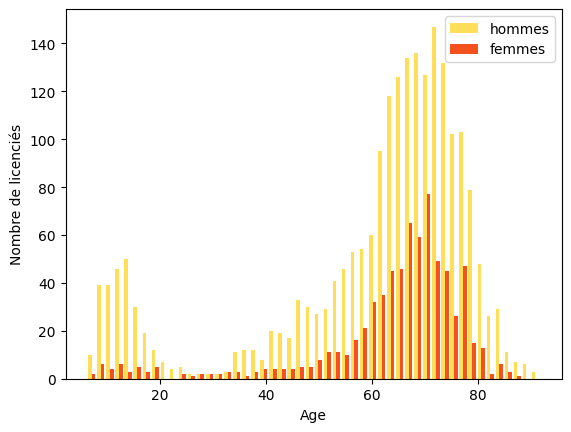

In [64]:
PATH_OUTPUT = Path.home() / Path("CODEP38") / Path('Temp')
df_tot_animateurs = pd.concat(df_animateur_list, axis=0)
df_tot_animateurs['Tel fixe'] = df_tot_animateurs['Tel fixe'].apply(normalize_num_tel)
df_tot_animateurs['Tel portable'] = df_tot_animateurs['Tel portable'].apply(normalize_num_tel)
df_tot_animateurs = df_tot_animateurs[['Club','N° Club','N°', 'Nom', 'Sexe',
       'Adresse email', 'Tel fixe', 'Tel portable',
       'Formation','Age','Flag']]

df_tot_animateurs.to_excel(r'c:\users\franc\Temp\spy.xlsx',index= None)

indicator_df = result[['ID','Nom du Club','Ville du Club','Territoire']].drop_duplicates()

dic_effectif,effectif_list_h, effectif_list_f = make_dic_age(root,year)
effectif_df = pd.DataFrame.from_dict(dic_effectif).T
effectif_df.columns=["ID","Age moyen","Age moyen homme","Age moyen femme","Age moyen adulte (>=18 ans)",
                     "Age moyen adulte (<18 ans)",
                     "Nombre d'hommes", "Nombre d'hommes (>=18 ans)",
                     "Nombre de femmes", "Nombre dde femmes (>=18 ans)",
                     "Pourcentage femme","Nombre total","efv"]
df_merged = indicator_df.merge(effectif_df, on='ID', how='left')
df_merged["points_AG"] = df_merged["Nombre total"].apply(nbr_point_vote)
df_merged.to_excel(root / Path('indicateurs_club.xlsx'),index=None)
age_moyen_copep38 =round( sum(effectif_df["Age moyen homme"]*
                              effectif_df["Nombre total"])/sum(effectif_df["Nombre total"]),2)

effectif_list = effectif_list_h + effectif_list_f 
age_copep38_adult_list = [x for x in effectif_list if x >= 18]
nbr_adults =  len(age_copep38_adult_list)
nbr_enfants = len(effectif_list)-len(age_copep38_adult_list)
age_moyen_copep38_adult = round(mean(age_copep38_adult_list),2)
_ = plt.hist([effectif_list_h,effectif_list_f], \
             bins=50, color=['#FFDE59',"#F4511E"] ) #rwidth=0.8,edgecolor='black'
title = f"Age moyen :{age_moyen_copep38} ans, Age moyen adult :{age_moyen_copep38_adult} ans"
title = title + "\n"
title = title + f"Nombre d'adultes {nbr_adults}, Nombre enfants {nbr_enfants}"
plt.legend(['hommes', 'femmes'])
plt.ylabel('Nombre de licenciés')
plt.xlabel('Age')
#plt.title(title)
plt.savefig(PATH_OUTPUT / Path('histo.jpeg'))
dic_stat = {}
dic_stat['Nbr_clubs'] = len(df_merged)
nbr_tot = df_merged['Nombre total'].sum()
dic_stat['Nbr_total'] = nbr_tot
dic_stat['Nbr_hommes'] = df_merged["Nombre d'hommes"].sum()
nbr_femmes = df_merged["Nombre de femmes"].sum()
dic_stat['Nbr_femmes'] = nbr_femmes
dic_stat['feminisation'] = round(100*nbr_femmes/nbr_tot,2)
dic_stat['Nbr_jeunes'] = nbr_tot - df_merged["Nombre d'hommes (>=18 ans)"].sum()-df_merged["Nombre dde femmes (>=18 ans)"].sum()
dic_stat['age_moyen_tot'] = age_moyen_copep38
dic_stat['age_moyen_adult'] = age_moyen_copep38_adult
dic_stat['efv'] = len(df_merged.query("efv == 'oui'"))
dic_stat['Nbr_median_cyclos'] = df_merged['Nombre total'].median()

df_merged = df_merged.fillna(0)
v = round(df_merged['Age moyen homme'].dot(df_merged["Nombre d'hommes"])/df_merged["Nombre d'hommes"].sum(),2)
dic_stat['age_moyen_homme'] = v
v = round(df_merged['Age moyen femme'].dot(df_merged["Nombre de femmes"])/df_merged["Nombre de femmes"].sum(),2)
dic_stat['age_moyen_femme'] = v

f = []
efv_d = df_merged.query("efv == 'oui'")
for idx,row in efv_d.iterrows():
    f.append(dict(id=str(row['ID']).zfill(5),
                  ville=row['Ville du Club'],
                  club=row['Nom du Club']))
dic_stat['f'] = f
  
print(PATH_OUTPUT / Path('histo.jpeg'))
print(root / Path('indicateurs_club.xlsx'))

## Plots the number of club member by genre

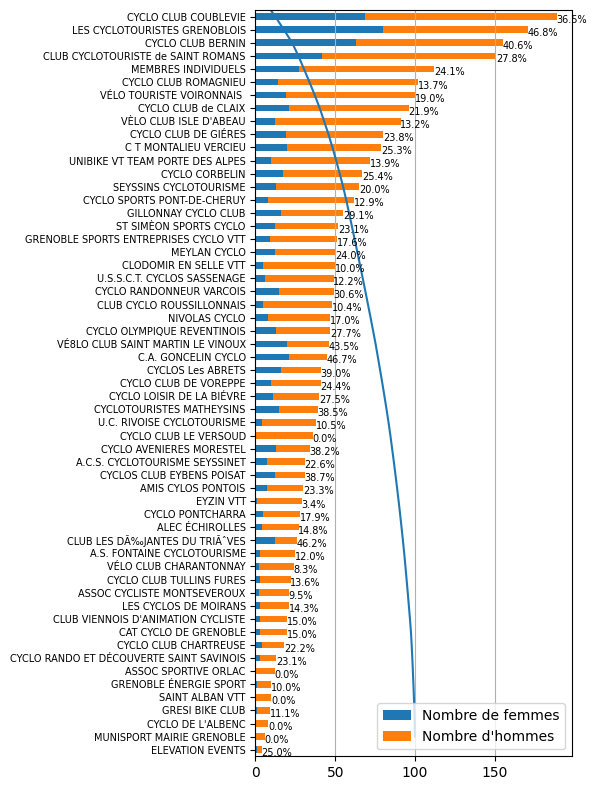

In [65]:
import numpy as np
def addlabels(x,y,lab):
    for i in range(len(x)):
        plt.text(x[i]-0.15,y[i]-0.5,lab[i],size=7)
        
df_merged = df_merged.sort_values(['Nombre total'])
df = df_merged[['Nom du Club','Nombre de femmes',"Nombre d'hommes"]]
#df.index = df_merged['Nom du Club']
ax = df.plot(kind='barh', stacked=True, figsize=(6,8))
ax.tick_params(axis='y', labelsize=7) 
lab = [str(round(100*x/(x+y),1))+"%" for x,y in zip(df['Nombre de femmes'],df["Nombre d'hommes"])]
x = [x+y for x,y in zip(df['Nombre de femmes'],df["Nombre d'hommes"])]
addlabels(x,
          range(len(df)),lab)
plt.yticks(range(len(df)), df['Nom du Club'])
plt.grid(which='major', axis='x')
plt.grid(which='minor', linestyle='--',axis='x')


df['tot']=df['Nombre de femmes']+df["Nombre d'hommes"]
df = df.sort_values(['tot'],ascending=False)
y = 100*np.cumsum(df['tot'].tolist())/df['tot'].sum()
x = list(range(1,len(y)+1))
plt.plot(y[::-1],x)
#plt.xlabel('Nombre de club')
#plt.ylabel('% du contingent')
#plt.grid(which='major', axis='x')
plt.grid(which='minor', linestyle='--',axis='x')
np.where(y>50)[0][0]
#plt.title('Sales Distribution by Product Type and Region (Horizontal)')
#plt.xlabel('Sales')
#plt.ylabel('Product Type')
plt.tight_layout()
file = PATH_OUTPUT / Path('nbr_adherents_club38.png')
plt.savefig(file)

## Fabrication du calendrier

In [66]:
import unicodedata

import os
import time
from pathlib import Path
from datetime import date
from collections import defaultdict

import pandas as pd

from docxtpl import DocxTemplate, InlineImage, RichText
from docxcompose.composer import Composer
from docx import Document as Document_compose
from docx.shared import Cm, Emu, Inches, Mm

def date_today():
    today = date.today()
    d = str(today.year)+str(today.month).zfill(2)+str(today.day).zfill(2)
    return d

def make_dic_rando(PATH_RANDO):

    df_rando = pd.read_excel(PATH_RANDO)
    dg = df_rando.groupby(['numero_federal'])
    rando_dict = defaultdict(lambda: '')
    for idx, v in dg:
        rando_dict[idx[0]] = ' ; '.join(v['nom_randonnee'].tolist())
    return rando_dict
    
def combine_all_docx(list_docx,year):

    """
    Merges all the docx file contained in `list_docx` 
    """
    filename_master = PATH_OUTPUT / Path('premiere-de-couverture-bureau.docx')
    number_of_sections = len(list_docx)
    master = Document_compose(filename_master)
    composer = Composer(master)
    for i in range(1, number_of_sections):
        doc_temp = Document_compose(list_docx[i])
        try:
            composer.append(doc_temp)
            time.sleep(0.1)
        except:
            pass
            
    file_name = f'ANNUAIRE_CoDep38_{date_today()}.docx'
    combine_file = PATH_SAUVEGARDE / file_name
    composer.save(combine_file)

def make_page_de_garde(dic_stat):
    #qrc_sejour.append(InlineImage(doc,qrc_name,Cm(1.5)))
    output_file = PATH_OUTPUT / Path( 'premiere-de-couverture-bureau.docx')
    
    template_docx = PATH_TEMPLATES  / Path('premiere-de-couverture-bureau-template.docx')
    doc = DocxTemplate(template_docx)
    file_image = PATH_OUTPUT / Path('histo.jpeg')
    
    dic_stat['image1'] = InlineImage(doc,r'C:/Users/franc/CODEP38/Temp/histo.jpeg',Cm(15)) 
    dic_stat['image2'] = InlineImage(doc,r"C:/Users/franc/CODEP38/Temp/nbr_adherents_club38.png",Cm(16)) 
    context = dic_stat
    doc.render(context)
    doc.save(output_file)

def make_table_matiere(club_list):

    output_file = PATH_OUTPUT / Path( 'liste_matiere.docx')
                
    context ={'year': year,
              'frameworks': club_list}
    template_docx = PATH_TEMPLATES  / Path('template_Liste_matiere_bureau.docx')
    doc = DocxTemplate(template_docx) 
    doc.render(context)
    doc.save(output_file)

def telephonne(x):
    if len(x):
        return x[0]
    return ''

def join_telephonne(t1,t2):
     if t1 == t2:
         t2 = ''
     if len(t1) and len(t2):
         return t1+' / '+t2
     elif len(t1):
         return t1
     else:
         return t2
         
def make_hyperlink(courriel,doc):
    
    rt = RichText()
    rt.add(courriel, 
           url_id=doc.build_url_id(courriel),
           font="Calibri",
           color='#3366CC',
           size = 20)
    
    return rt

def builds_organisation_docx(result,year,template_path_docx,PATH_RANDO):

    def correspondante_feminine(id):
        try:
           t1 = telephonne(result.query('ID == @id and F == "F"')['Tel portable'].tolist())
           t2 = telephonne(result.query('ID == @id and F == "F"')['Tel fixe'].tolist())
           telephone = join_telephonne(t1,t2)
           return (result.query('ID == @id and F == "F"')['Nom'].tolist()[0],
                   result.query('ID == @id and F == "F"')['Adresse'].tolist()[0],
                   telephone,
                   make_hyperlink(result.query('ID == @id and F == "F"')['Adresse email'].tolist()[0],doc),)
        except:
            return ('','','','')

    def correspondante(id):
        t1 = telephonne(result.query('ID == @id and C == "C"')['Tel portable'].tolist())
        t2 = telephonne(result.query('ID == @id and C == "C"')['Tel fixe'].tolist())
        telephone = join_telephonne(t1,t2)
        try:
           return (result.query('ID == @id and C == "C"')['Nom'].tolist()[0],
                   result.query('ID == @id and C == "C"')['Adresse'].tolist()[0],
                   telephone,
                   make_hyperlink(result.query('ID == @id and C == "C"')['Adresse email'].tolist()[0],doc),)
        except:
            return ('','','','')

    def correspondante_securite(id):
        t1 = telephonne(result.query('ID == @id and D == "D"')['Tel portable'].tolist())
        t2 = telephonne(result.query('ID == @id and D == "D"')['Tel fixe'].tolist())
        telephone = telephone = join_telephonne(t1,t2)
        try:
           return (result.query('ID == @id and D == "D"')['Nom'].tolist()[0],
                               result.query('ID == @id and D == "D"')['Adresse'].tolist()[0],
                               telephone,
                               make_hyperlink(result.query('ID == @id and D == "D"')['Adresse email'].tolist()[0],doc),)
        except:
            return ('','','','')
    #file_mf = r"C:\Users\franc\Dropbox\Codep 38\Année 2026\Clubs_38_au_12_01_2026.xlsx"
    #web_df = pd.read_excel(file_mf)
    #web_df.rename(columns={'N°': 'ID',}, inplace=True)

    def correspondante_jeune(id):
        t1 = telephonne(result.query('ID == @id and J == "J"')['Tel portable'].tolist())
        t2 = telephonne(result.query('ID == @id and J == "J"')['Tel fixe'].tolist())
        telephone = telephone = join_telephonne(t1,t2)
        try:
           return (result.query('ID == @id and J == "J"')['Nom'].tolist()[0],
                               result.query('ID == @id and J == "J"')['Adresse'].tolist()[0],
                               telephone,
                               make_hyperlink(result.query('ID == @id and J == "J"')['Adresse email'].tolist()[0],doc),)
        except:
            return ('','','','')

    def president(result,id):
        
        l = result.query('ID == @id and P=="P"')
        np = l['Nom'].tolist()[0]
        ap = l['Adresse'].tolist()[0]
        t1 = telephonne([l['Tel portable'].tolist()[0]])
        t2 = telephonne([l['Tel fixe'].tolist()[0]])
        tp = join_telephonne(t1,t2)
        wp = make_hyperlink(l['Adresse email'].tolist()[0],doc)
        nbr_p = 1
        
        add_2 = l['Adresse email 2'].tolist()[0]
        if add_2:
            add_2 = make_hyperlink(add_2,doc)
        else:
            add2 = ''
        np2 = ''
        ap2 = ''
        tp2 = ''
        wp2 = ''
        add_22= ''   
        if len(l)>1:
            nbr_p = 2
            np2 = l['Nom'].tolist()[1]
            ap2 = l['Adresse'].tolist()[1]
            t1 = telephonne([l['Tel portable'].tolist()[1]])
            t2 = telephonne([l['Tel fixe'].tolist()[1]])
            tp2 = join_telephonne(t1,t2)
            wp2 = make_hyperlink(l['Adresse email'].tolist()[1],doc)
            
            add_2 = l['Adresse email 2'].tolist()[1]
            if add_2:
                add_22 = make_hyperlink(add_2,doc)
            else:
                add22 = ''
        return (np,ap,tp,wp,add_2,np2,ap2,tp2,wp2,add_22,nbr_p)         
        
        
    long = 1  # for future use
    file_list = []
    list_docx = []
    club_list = []
    idx = 0
    result.rename(columns={'Nom du Club': 'club', 
                           'Ville du Club': 'ville'}, inplace=True) 
    result = result.fillna(' ')
    for id in result['ID'].unique():
        
        rando_dict = make_dic_rando(PATH_RANDO)
        
        formation_dict = {}
        id_str = str(id)
        formation_dict['Animateur Club'] = ''
        formation_dict['Initiateur fédéral'] = ''
        formation_dict['Moniteur Fédéral'] = ''
        for x,y in df_tot_animateurs.query('IDC==@id_str').groupby(['Formation'])['Nom']:
            formation_dict[x[0]] = ', '.join(y.tolist())
        
        if result.query('ID==@id')['nbr_president'].tolist()[0]==1:
            doc = DocxTemplate(template_path_docx)
        else:
            doc = DocxTemplate(template_path_docx_2)

        club_list.append(str(id).zfill(5) + ' - ' + result.query('ID == @id')['club'].tolist()[0])

        
        web_list = result.query('ID==@id')['Site']
        web_list = [x for x in  web_list if isinstance(x,str)]
        if len(web_list)>0:
            web_site = make_hyperlink(web_list[0],doc)
        else:
            web_site = ''

        (np,ap,tp,wp,add_2,np2,ap2,tp2,wp2,add_22,nbr_p) = president(result,id)
        (nf,af,tf,wf)=correspondante_feminine(id)
        (nd,ad,td,wd)=correspondante_securite(id)
        (nc,ac,tc,wc)=correspondante(id)
        (nj,aj,tj,wj)=correspondante_jeune(id)
        
        secretaire = result.query('ID == @id and S == "S"')['Nom']
        ns_ = ''
        as_ = ''
        ws_ = ''
        ts = ''
        if len(secretaire) >0:
            ns_ = secretaire.tolist()[0]
            as_ = result.query('ID == @id and S == "S"')['Adresse'].tolist()[0]
            ws_ = make_hyperlink(result.query('ID == @id and S == "S"')['Adresse email'].tolist()[0],doc)
            t1 = telephonne(result.query('ID == @id and S == "S"')['Tel portable'].tolist())
            t2 = telephonne(result.query('ID == @id and S == "S"')['Tel fixe'].tolist())
            ts = join_telephonne(t1,t2)

        tresorier = result.query('ID == @id and T == "T"')['Nom']
        nt_ = ''
        at_ = ''
        wt_ = ''
        tt = ''
        if len(tresorier) >0:
            nt_ = tresorier.tolist()[0]
            at_ = result.query('ID == @id and T == "T"')['Adresse'].tolist()[0]
            wt_ = make_hyperlink(result.query('ID == @id and T == "T"')['Adresse email'].tolist()[0],doc)
            t1 = telephonne(result.query('ID == @id and T == "T"')['Tel portable'].tolist())
            t2 = telephonne(result.query('ID == @id and T == "T"')['Tel fixe'].tolist())
            tt = join_telephonne(t1,t2) 
       
        stat = df_merged.query('ID==@id')
        nbr_tot = stat['Nombre total'].tolist()[0]
        nbr_hommes = stat["Nombre d'hommes"].tolist()[0]
        nbr_jeunes = nbr_tot - stat["Nombre d'hommes (>=18 ans)"].tolist()[0] - stat["Nombre dde femmes (>=18 ans)"].tolist()[0]
        nbr_femmes = stat['Nombre de femmes'].tolist()[0]
        age_moyen = stat['Age moyen'].tolist()[0]
        efv = stat['efv'].tolist()[0]
        
        stat_str = f"Effectif :{nbr_tot} ({nbr_femmes} femmes ,"
        stat_str = stat_str + f"{nbr_hommes} hommes) Nombre de jeunes :{nbr_jeunes}  Age moyen : {age_moyen} ans"
        stat_str = stat_str + f"   EFV :{efv.upper()}"
        
        flag_adress = False
        f ={'Nom_club':  result.query('ID == @id')['club'].tolist()[0],
            'ville':  result.query('ID == @id')['ville'].tolist()[0],
            'site':  web_site,
            'id': str(id).zfill(5),
            'np': np,
            'ap': ap if flag_adress else '',
            'tp': tp,
            'wp': wp,
            'w2p': add_2,
            'np2': np2,
            'ap2': ap2 if flag_adress else '',
            'tp2': tp2,
            'wp2': wp2,
            'w2p2': add_22,
            'ns': ns_,
            'as': as_ if flag_adress else '',
            'ts': ts,
            'ws': ws_,
            'nt': nt_,
            'at': at_ if flag_adress else '',
            'tt': tt,
            'wt': wt_,
            'nc': nc,
            'ac': ac if flag_adress else '',
            'tc': tc,
            'wc': wc,
            'nd': nd,
            'ad': ad if flag_adress else '',
            'td': td,
            'wd': wd,
            'nf': nf,
            'af': af if flag_adress else '',
            'tf': tf,
            'wf': wf,
            'nj': nj,
            'aj': aj if flag_adress else '',
            'tj': tj,
            'wj': wj,
            'aclub': formation_dict['Animateur Club'],
            'ifed': formation_dict['Initiateur fédéral'],
            'mfed': formation_dict['Moniteur Fédéral'],
            'stat': stat_str,
            'rando' : rando_dict[id]}  

        doc.render(f)
        #    
        output_file = PATH_OUTPUT / Path("bureau"+str(idx)+".docx")
        doc.save(output_file)
        list_docx.append(output_file)
    
        idx += 1
        
    return list_docx, club_list

year = 2026
PATH_OUTPUT = Path.home() / Path("CODEP38") / Path('Temp')
PATH_SAUVEGARDE = Path.home() / Path('Dropbox\Codep 38') / Path("Année " + str(year)) 
PATH_TEMPLATES = Path.home() / Path('Dropbox\Codep 38') / Path("Année " + str(year)) 
PATH_TEMPLATES = PATH_TEMPLATES / Path('Secretariat') /  Path("TEMPLATES")

PATH_RANDO = Path.home() / Path('Dropbox\Codep 38') / Path("Année " + str(year)) 
PATH_RANDO = PATH_RANDO / Path(r"Calendrier\randonnees\SYNTHESE") / Path(f"randos_synthese{year}_save.xlsx")

template_path_docx = PATH_TEMPLATES / Path("Template_bureau.docx")
template_path_docx_2 = PATH_TEMPLATES / Path("Template_bureau_2.docx")
df_tot_animateurs.rename(columns={'N° Club':'IDC'},inplace=True)
list_docx,  club_list = builds_organisation_docx(result,year,template_path_docx,PATH_RANDO)
make_table_matiere(club_list)
list_docx.insert(0, PATH_OUTPUT / Path('liste_matiere.docx'))
make_page_de_garde(dic_stat)
list_docx.insert(0, PATH_OUTPUT / Path('premiere-de-couverture-bureau.docx'))
combine_all_docx(list_docx,year)

file_name = f'ANNUAIRE_CoDep38_{date_today()}.docx'
print("FINISHED")

FINISHED


In [71]:
set_president = {"btlevare@gmail.com",
"patrick.lacheau@free.fr",
"contact@cyclo-voiron.org",
"jeannoelcolle065@gmail.com",
"philippesalvi38@gmail.com",
"catherine.caillau@cycloclubclaix.org",
"cyclomatheysins@gmail.com",
"louis.peron@orange.fr",
"ma.chevallier@orange.fr",
"cspcisere@gmail.com",
"taveljp@gmail.com",
"cyclos.seyssinet@gmail.com",
"serge.robert0922@orange.fr",
"paulette.digaud@orange.fr",
"roger.cerantola@aliceadsl.fr",
"jeanyvesodier@hotmail.fr",
"jarrige.pascal@bbox.fr",
"joelle.mingat@wanadoo.fr",
"coreventin@gmail.com",
"roger.levayer@orange.fr",
"humeau-ger@wanadoo.fr",
"bernard.meunier89@gmail.com",
"denisvassor@gmail.com",
"cyclo-eybenspoisat@orange.fr",
"benoit.lebrun38@orange.fr",
"jerome.marquier@live.fr",
"didierquily@yahoo.com",
"edwin.monnet@gmail.com",
"crvarces@gmail.com",
"cyclopontois3873@gmail.com",
"jac2vauboin@free.fr",
"daniel.38sz53@gmail.com",
"cdetroyat@gmail.com",
"antoine.maiello@axa.fr",
"calemard.hubert@orange.fr",
"christophe.genevey@orange.fr",
"christophe.napoleoni@wanadoo.fr",
"zabeth.pascal@wanadoo.fr",
"president@ucrives.fr",
"charantonnayveloclub@gmail.com",
"paul.chomard@gmail.com",
"patrick.courtial9@orange.fr",
"veloroussillon38@orange.fr",
"gilles.jouvel@orange.fr",
"cclv38@yahoo.fr",
"claude.bronner626@wanadoo.fr",
"eyzinvtt@gmail.com",
"frederic.tedesco@orange.fr",
"veloclub.ida@gmail.com",
"pascal.baudrand1@gmail.com",
"pascalvuilloz@sfr.fr",
"dominique.tabaret@wanadoo.fr",
"emmanuelruiz38@gmail.com",
"yoann.jegou@orange.fr",
"gresibikeclub@gmail.com"}

from pathlib import Path
import pandas as pd

year = 2026
PATH = Path.home() / Path(r'Dropbox\Codep 38') / Path("Année " + str(year)) 
file_name = PATH / Path(f'bureau_club_codep38_20260330.xlsx')

result = pd.read_excel(file_name )
set_fb = set(result.query('P=="P"')['Adresse email'])

#df = pd.read_excel(Path(r"C:\Users\franc\Temp") / Path('courriel-president_assoconnect.xlsx'))

print(set_president-set_fb)
print()
print(set_fb-set_president)


{'charantonnayveloclub@gmail.com', 'cyclopontois3873@gmail.com', 'coreventin@gmail.com', 'cspcisere@gmail.com', 'president@ucrives.fr', 'bernard.meunier89@gmail.com', 'cyclos.seyssinet@gmail.com', 'contact@cyclo-voiron.org', 'cclv38@yahoo.fr', 'crvarces@gmail.com', 'joelle.mingat@wanadoo.fr', 'gilles.jouvel@orange.fr', 'calemard.hubert@orange.fr', 'cyclomatheysins@gmail.com', 'christophe.genevey@orange.fr', 'eyzinvtt@gmail.com', 'emmanuelruiz38@gmail.com'}

{'joel.savignon@orange.fr', 'claudegrando@orange.fr', 'o.constant@wanadoo.fr', 'jack.marchioni@wanadoo.fr', 'jdempas@free.fr', 'gontardgeorges6@gmail.com', 'jmdegrange01@gmail.com', 'ebert-w-y@orange.fr', 'lo.barthalay@gmail.com', 'yves.monin38@gmail.com', 'yoan.dercourt38@gmail.com', 'dupuis.x@icloud.com', 'pierrotgrosgaz@gmail.com', 'bressand.georges@orange.fr', 'stephane.billard.velo@gmail.com', 'dchevallierpapet@gmail.com', 'jluc.puyjarinet@gmail.com', 'raphael.armanet@neuf.fr', 'orussier@gmail.com', 'jmarnouil@gmx.fr'}


# Comparaison avec AssoConnect

In [62]:
from pathlib import Path
import pandas as pd

year = 2026
PATH_OUTPUT = Path.home() / Path("CODEP38") / Path('Temp')
PATH_SAUVEGARDE = Path.home() / Path(r'Dropbox\Codep 38') / Path("Année " + str(year)) 
file_name = f'bureau_club_codep38_{date_today()}.xlsx'
file = PATH_SAUVEGARDE / file_name

result = pd.read_excel(file)
result = result.query("P=='P'")
result['Nom'] = result['Nom'].apply(lambda x: x.split(' ')[0])

#df = pd.read_excel(Path(r"C:\Users\franc\Temp") / Path('courriel-president_assoconnect.xlsx'))

file = "Liste des présidents au 2026-03-30 (a jour).xlsx"
PATH = PATH_SAUVEGARDE / Path(r"Secretariat")
df = pd.read_excel(PATH / Path(file))

set_jp = dict(zip(df['Email'],df['Nom']))
set_fb = dict(zip(result.query('P=="P"')['Adresse email'],result.query('P=="P"')['Nom']))
diff_items = set(set_fb.items()) - set(set_jp.items())

print("françois versus Jean-Paul")
for t in diff_items:
    print(t[0],t[1])
print()
print(set(set_fb.values())-set(set_jp.values()))

diff_items = set(set_jp.items()) - set(set_fb.items())
print()
print()
print("Jean-Paul versus François")
for t in diff_items:
    print(t[0],t[1])

print()
print(set(set_jp.values())-set(set_fb.values()))

françois versus Jean-Paul
dchevallierpapet@gmail.com CHEVALLIER
benoit.lebrun38@orange.fr LE
ebert-w-y@orange.fr EBERT

{'LE', 'EBERT'}


Jean-Paul versus François
benoit.lebrun38@orange.fr LE BRUN
ebert-w-y@orange.fr EBERT WALKENS
dchevallierpapet@gmail.com CHEVALIER

{'EBERT WALKENS', 'LE BRUN', 'CHEVALIER'}


## Changement de président

In [ ]:
import pandas as pd
file = "bureau_club_codep38_20260120.xlsx"
df = pd.read_excel(Path(r"C:\Users\franc\CODEP38\2025") / Path(file))
result = pd.read_excel(Path(r"C:\Users\franc\CODEP38\2026") / Path(file))
set1 = dict(zip(df.query('P=="P"')['ID'],df.query('P=="P"')['Nom']))
dic_nom = dict(zip(df['ID'],df['Nom du Club']))
set2 = dict(zip(result.query('P=="P"')['ID'],result.query('P=="P"')['Nom']))
diff_items = set(set2.items()) - set(set1.items())
club = []
nom_2026 = []
nom_2025 = []
idc = []
for t in diff_items:
    try:
        club.append(dic_nom[t[0]])
        idc.append(t[0])
        nom_2026.append(t[1])
        nom_2025.append(set1[t[0]])
    except:
        pass
              
dg = pd.DataFrame(list(zip(club,idc,nom_2026,nom_2025)),columns=['club', 'ID', 'Président 2026', 'Président 2025'])
dg.to_excel(r"c:\users\franc\Temp\bidon.xlsx",index=False)
diff_items = set(set1.keys()) - set(set2.keys())
print(len(diff_items))
for x in diff_items :
    print(x, dic_nom[x])


In [ ]:
import numpy as np
df['tot']=df['Nombre de femmes']+df["Nombre d'hommes"]
df = df.sort_values(['tot'],ascending=False)
y = 100*np.cumsum(df['tot'].tolist())/df['tot'].sum()
x = list(range(1,len(y)+1))
plt.plot(x,y)
plt.xlabel('Nombre de club')
plt.ylabel('% du contingent')
plt.grid()
np.where(y>50)[0][0]

# Evolution des effectifs hommes/femmes du Codep38

In [ ]:
import os
from pathlib import Path
import matplotlib.pyplot as plt

import pandas as pd

def stat_effectif_codep(year):

    root = Path.home() / Path('Dropbox\Codep 38') / Path("Année " + str(year)) / Path('Secretariat')
    root = root / Path('EVOLUTION') / Path('codep_effectif')
    
    dic_effectif = {}
    dic_nbr_club = {}
    dic_pourcentage = {}
    for file in [x for x in os.listdir(root) if x.endswith('.xlsx')]:
        df = pd.read_excel(root / Path(file),skipfooter=1,skiprows=2,header=None)
        df.columns = ['id_club','nom_club','renouvellement_homme','renouvellement_femme','creation_homme','creation_femme',
                      'total_homme','total_femme']
        df['total_femme'] =df['total_femme'].fillna(0)
        df['total_homme'] =df['total_homme'].fillna(0)
        dic_effectif[file[0:4]] = [sum(df['total_homme']),sum(df['total_femme'])]
        dic_nbr_club[file[0:4]] = [len(df)]
        dic_pourcentage[file[0:4]] = [100*sum(df['total_femme'])/(sum(df['total_femme'])+sum(df['total_homme']))]
    dg = pd.DataFrame.from_dict(dic_effectif).T
    dg.columns = ['Homme','Femme']
    ax = dg.plot.bar(rot=90,stacked=True)
    plt.grid()
    #print(dg)
    dh = pd.DataFrame.from_dict(dic_nbr_club).T
    dh.columns = ['# club']
    ax = dh.plot.bar(rot=90,stacked=True)
    plt.grid()
    
    dp = pd.DataFrame.from_dict(dic_pourcentage).T
    dp.columns = ['poucentage de femmme']
    ax = dp.plot.bar()

year = 2026
stat_effectif_codep(year)

# Analyse de l'évolution de l'âge du CODep38

In [ ]:
import os
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

def stat_age_codep(year):
    root = Path.home() / Path('Dropbox\Codep 38') / Path("Année " + str(year)) / Path('Secretariat')
    root = root / Path('EVOLUTION') / Path('codep_age')
    
    dic_age = {}
    dic_age_genre = {}
    for file in [x for x in os.listdir(root) if x.endswith('.xlsx')]:
        df = pd.read_excel(root / Path(file),skipfooter=1)
        df = df.fillna(0)
        df = df.fillna(0)
        df['mean']=df.apply(lambda row:row['Âge']*row['Total'],axis=1)
        dic_age[file[0:4]] = [sum(df['mean'])/sum(df['Total'])]
        df['mean_h']=df.apply(lambda row:row['Âge']*row['Homme'],axis=1)
        df['mean_f']=df.apply(lambda row:row['Âge']*row['Femme'],axis=1)
        dic_age_genre[file[0:4]] = [sum(df['mean_h'])/sum(df['Homme']),
                              sum(df['mean_f'])/sum(df['Femme'])]
    
    dg = pd.DataFrame.from_dict(dic_age).T
    dg.columns = ['Age moyen']
    dg.to_excel(r"c:\users\franc\Temp\spy.xlsx")
    ax = dg.plot.bar(rot=90,stacked=True)
    plt.ylim(40,60)
    
    dg = pd.DataFrame.from_dict(dic_age_genre).T
    dg.columns = ['Age moyen homme','Age moyen femme']
    ax = dg.plot.bar(rot=90)
    plt.ylim(40,75)

year = 2026
stat_age_codep(year)

# Analyse de l'évolution des prises de licences du CoDep38

In [ ]:
import os
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

year = 2026
root = Path.home() / Path('Dropbox\Codep 38') / Path("Année " + str(year)) / Path('Secretariat')
root = root / Path('EVOLUTION') / Path('codep38_licences')

df = pd.read_excel(root / Path('2025.xlsx'),skiprows=1)
df['label'] = df['Date de début']+" - " +df['Date de fin']
df = df.fillna(0)

dh = df[['label','Dif. Renouvellement licences','Dif. Créations licences']]
dh.index = dh['label']
dh = dh.loc[::-1]
ax = dh.plot.bar(rot=90,stacked=True)
print(sum(df['Dif. Renouvellement licences']),sum(df['Dif. Créations licences']))

dg = df[['label','Création licences','Renouvellement Licences']]
dg.index = dg['label']
dg = dg.loc[::-1]
ax = dg.plot.bar(rot=90,stacked=True,color=['red','green'])
plt.tight_layout()


plt.savefig(r"c:\users\franc\Temp\inscriptions.png")

# ANALYSE RANDONNEES

In [ ]:
# Exploitation des fiches challenge
# Standard library imports
from collections import defaultdict
import os
import math
import pathlib
from pathlib import Path
from operator import itemgetter

# Third party imports
import xlrd
import pandas as pd
import matplotlib.pyplot as plt

def addlabels(x,y,lab):
    for i in range(len(x)):
        plt.text(x[i]-0.15,y[i],lab[i],size=7)

def nan2zero(s):
    if isinstance(s,float):
        return int(s)
    return 0
    
def extraction():
    d = defaultdict(list)
    club_route = defaultdict(list)
    data = defaultdict(list)
    #club_gravel = defaultdict(list)
    for file in [x for x in os.listdir(root) if x.endswith('.xls') ]:
        print(file)
        workbook = xlrd.open_workbook(root / Path(file), formatting_info=True)
        worksheet_route = workbook.sheet_by_name('1 ROUTE ')
        worksheet_vtt = workbook.sheet_by_name('2 VTT')
        worksheet_pedestre = workbook.sheet_by_name('4 MARCHE')
        worksheet_gravel = workbook.sheet_by_name('3 GRAVEL')
        if worksheet_route.cell_value(3,2) != '':
            nom_rando = worksheet_route.cell_value(3,2)
            d['nom_rando'].append(nom_rando )
        else:
            nom_rando = worksheet_vtt.cell_value(3,2)
            d['nom_rando'].append(nom_rando)
        d['route'].append(worksheet_route.cell_value(16,7))
        d['vtt'].append(worksheet_vtt.cell_value(16,7))
        d['pedestre'].append(worksheet_pedestre.cell_value(16,7))
        d['gravel'].append(worksheet_gravel.cell_value(16,7))
        d['non_ffct'].append(worksheet_pedestre.cell_value(15,7)+
                             worksheet_route.cell_value(15,7)+
                             worksheet_gravel.cell_value(15,7)+
                             worksheet_vtt.cell_value(15,7))
        i = 21
        while worksheet_route.cell_value(i,1) or i>100:
            data['rando'].append(nom_rando)
            data['type'].append('route')
            data['club'].append(worksheet_route.cell_value(i,2))
            data['dep'].append(str(int(worksheet_route.cell_value(i,3))))
            data['nbr_cyclos'].append(worksheet_route.cell_value(i,7))

            club_route[nom_rando].append((worksheet_route.cell_value(i,1),
                                    worksheet_route.cell_value(i,7),'route'))
            i += 1
        
        i = 21
        while worksheet_vtt.cell_value(i,1) or i>100:
            data['rando'].append(nom_rando)
            data['type'].append('vtt')
            data['club'].append(worksheet_vtt.cell_value(i,2))
            data['dep'].append(str(int(worksheet_vtt.cell_value(i,3))))
            data['nbr_cyclos'].append(worksheet_vtt.cell_value(i,7))

            club_route[nom_rando].append((worksheet_vtt.cell_value(i,1),
                                    worksheet_route.cell_value(i,7),'vtt'))
            i += 1
        
        i = 21
        while worksheet_gravel.cell_value(i,1) or i>100:
            data['rando'].append(nom_rando)
            data['type'].append('gravel')
            data['club'].append(worksheet_gravel.cell_value(i,2))
            data['dep'].append(str(int(worksheet_gravel.cell_value(i,3))))
            data['nbr_cyclos'].append(worksheet_gravel.cell_value(i,7))
            club_route[nom_rando].append((worksheet_gravel.cell_value(i,1),
                                          
                                    worksheet_route.cell_value(i,7),'gravel'))
            i += 1  
        d['# cub_ffct'].append(len(set(map(itemgetter(0), club_route[nom_rando]))))
    return d,club_route,data
year = 2024
root = Path(r"C:\Users\franc\CODEP38") / Path(str(year))/ Path("fiches_challenge")
d,club_route,data = extraction()

df = pd.DataFrame(d)
df['tot'] = df['route'] + df['vtt'] + df['pedestre']+df['gravel']
df = df.sort_values(['tot'])
df.to_excel(root / Path('STAT') / Path('participation_rando_club38.xlsx'),index=False)
#df = df.drop('tot', axis=1)
df.index = df['nom_rando']
ax = df[['route','vtt','pedestre','gravel']].plot(kind='barh', stacked=True, figsize=(8,8))
ax.tick_params(axis='y', labelsize=7)
x = [int(x+y+z+v) for x,y,z,v in zip(df['route'],
                                     df["vtt"],
                                     df["pedestre"],
                                     df["gravel"]) ]
lab = [str(round(100-100*int(w)/int(x+y+z+v),1))+"%" if int(x+y+z+v)>0 else '' for x,y,z,v,w in zip(df['route'],
                                     df["vtt"],
                                     df["pedestre"],
                                     df["gravel"],
                                     df["non_ffct"]) ]
addlabels(x,
          range(len(df)),lab)
plt.yticks(range(len(df)), df['nom_rando'])

plt.ylabel('')
plt.grid(which='major', axis='x')


plt.tight_layout()
plt.savefig(root / Path('STAT') /Path('participation_rando_club38.png'))

dg = pd.DataFrame.from_dict(data)
dg.to_excel(r'c:\users\franc\Temp\spy.xlsx',index=None)


In [ ]:
root

In [ ]:
for file in [x for x in os.listdir(root) if x.endswith('.xlsx') ]:
    print(file)
    df = pd.read_excel(root / Path(file))
    df.to_excel(r"c:\users\franc\Temp\bidon.xls", engine="xlwt")
    break

In [ ]:

dg = dg.query('dep=="38"')
dg.to_excel(r'c:\users\franc\Temp\spy1.xlsx',index=None)
dg.groupby(['club'])['nbr_cyclos'].sum().to_excel(r'c:\users\franc\Temp\spy.xlsx')

In [ ]:
def addlabels(x,y,lab):
    for i in range(len(x)):
        plt.text(x[i]-0.15,y[i],lab[i],size=9)
ax = df[['# cub_ffct']].plot(kind='barh', stacked=True, figsize=(8,8))
ax.tick_params(axis='y', labelsize=9)
addlabels(df['# cub_ffct'].tolist(),
          range(len(df)),df['# cub_ffct'].tolist())
plt.ylabel('')
plt.grid(which='major', axis='x')


plt.tight_layout()
plt.savefig(root / Path('STAT') /Path('nbr_club_ffct.png'))

In [ ]:
df

In [ ]:
from operator import itemgetter
club_id ='00212'
for k, value in club_route.items():
    list_club = list(map(itemgetter(0), value))
    if club_id in list_club:
        club_nb_participations = list(map(itemgetter(1), value))
        list_club.index(club_id)
        print(k,club_nb_participations[list_club.index(club_id)])

In [ ]:
from operator import itemgetter
club_id ='00212'
for k, value in club_vtt.items():
    list_club = list(map(itemgetter(0), value))
    if club_id in list_club:
        club_nb_participations = list(map(itemgetter(1), value))
        list_club.index(club_id)
        print(k,club_nb_participations[list_club.index(club_id)])

In [ ]:
import numpy as np
def func(pct, allvalues):
        absolute = round(pct / 100.*np.sum(allvalues),0)
        #return "{:.1f}%\n({:d})".format(pct, absolute)
        label = f"{int(round(absolute,1))}\n{round(pct,1)} %"
        return label

dg = pd.DataFrame({'sum': [df['route'].sum(), df['vtt'].sum() , df['pedestre'].sum(),
                           df['gravel'].sum()],
                   },
                  index=['route', 'vtt', 'pedestre','gravel'])
explode_dic = {'route':0.0,
                   'vtt':0.2,
                   'pedestre':0.2,
                   'gravel':0.2,
                   }

plot = dg.plot.pie(y='sum', figsize=(5, 5),
                   explode = explode_dic.values(),
                   autopct = lambda pct: func(pct, dg['sum'].tolist()),
                  textprops={'fontsize': 10})

plt.ylabel('')
plt.tight_layout()
plt.savefig(root / Path('STAT') / 'pie_plot.png')


In [ ]:
import numpy as np
df['tot']=df['route']+df['vtt']
df['tot'].hist(bins=50)
rando = [x for x in df['tot'] if x !=0]
np.median(rando),np.mean(rando),len(rando)

In [ ]:
root / Path('STAT') /Path('participation_rando_club38.png')

In [ ]:
def addlabels(x,y,lab):
    for i in range(len(x)-1):
        plt.text(x[i]+0.5,y[i]+0.5,int(lab[i]),size=10)

age = [13]*4+[18]*3+[23]*5+[28]*9+[33]*15+[38]*41+[43]*44+[48]*30+[53]*25+[58]*23+[63]*10+[68]*10+[73]*2+[78]*2
h = plt.hist(age,bins=14,rwidth=0.9,color='#fdd835')

addlabels(h[1],h[0],h[0])
plt.xticks(fontsize=15)
plt.title(f"Nombre d'adhérents : {len(age)},  âge moyen: {round(np.mean(age),1)} ans \n 181 hommes (81 %) 42 femmes (20 %)")
plt.tight_layout()
plt.savefig(r'c:\users\franc\Temp\hist_age_1987.png')

In [ ]:
def addlabels(x,y,lab):
    for i in range(0,len(x)):
        print(x,y,i)
        plt.text(x[i]-1.25,y[i]+0.2,int(lab[i]),size=15)

fig, ax = plt.subplots(figsize=(7,7))
effectif = {'Age':[13]*4+[18]*3+[23]*5+[28]*9+[33]*15+[38]*41+[43]*44+[48]*30+[53]*25+[58]*23+[63]*10+[68]*10+[73]*2+[78]*2}
effectif = pd.DataFrame(data=effectif)
effectif['age group'] = pd.cut(effectif.Age, bins=range(10, 80, 5), right=False)
result_hist = effectif.groupby(['age group']).count()
result_hist.plot.bar(ax=ax,
                     color='#fdd835',
                     edgecolor='black', 
                     width=0.8)
addlabels(range(1,14),result_hist.Age.tolist(),result_hist.Age.to_list())
ax.set(yticklabels=[]) # remove the tick labels
plt.xticks(fontsize=15)
plt.xlabel('')
titre = f"Nombre d'adhérents : {len(age)},  âge moyen: {round(np.mean(age),1)} ans \n 181 hommes (81 %) 42 femmes (20 %)"
plt.title(titre,fontsize=20)
plt.tight_layout()
plt.savefig(r'c:\users\franc\Temp\hist_age_1987.png')

In [ ]:
result_hist.in

In [ ]:
from pathlib import Path
import pandas as pd

year = 2026
root = Path(r"C:\Users\franc\Dropbox\Codep 38") / Path("Année " + str(year)) / Path("Calendrier")

df = pd.read_excel(root / Path("2026 Synthèse demande club.xlsx"))




In [ ]:
df = pd.read_excel(r"c:\users\franc\Temp\Classeur1.xlsx")
df = df.fillna('')

df_list = []
for x,y in df.groupby('Nom'):
    if len(y)>1:
        for col in ["P","C","S","D","T","J","F"]:
            y[col] = ''.join(y[col].tolist())
        y = y.drop_duplicates()
    df_list.append(y)
    
df_tot = pd.concat(df_list, axis=0)
        

          

In [43]:
from collections import defaultdict

df_rando = pd.read_excel(r"C:\Users\franc\CODEP38\2026\randonnees\SYNTHESE\randos_synthese2026_save.xlsx")
dg = df_rando.groupby(['numero_federal'])
rando_dict = defaultdict(lambda: '')
for idx, v in dg:
    rando_dict[idx[0]] = '; '.join(v['nom_randonnee'].tolist())
rando_dict

defaultdict(<function __main__.<lambda>()>,
            {212: "LES BOUCLES GRENOBBISES; BREVET DE RANDONNEUR DE L'OISANS (BRO)",
             281: 'RANDONNÉE DES DIX COMMUNES; BOURSE AUX VÉLOS; RANDONNÉE DE L’ESPOIR',
             890: 'LES 3 LACS; LE RONCEVEAU',
             1109: 'RANDONNÉE DE L’OBIOU ET MUROISE VTT',
             1125: 'LES ECUREUILS',
             1184: 'RANDONNEE DU SUD GRESIVAUDAN; RANDONNEE DE LA RAVIOLE',
             1598: 'RANDONNEE DES COTEAUX CYCLO CLUB TULLINS FURES',
             1909: 'VIRÉE EN VERCORS - SOUVENIR DUBOIS JACOB; RANDONNÉE DES CASTORS',
             2005: 'LA SEYSSINOISE',
             2015: 'BREVET DES RANDONNEURS MONDIAUX  200 KM; RANDONNEE DE PRINTEMPS; BREVET DES RANDONNEURS MONDIAUX  400 KM; BREVET DES RANDONNEURS MONDIAUX  600 KM; RANDONNEE DU VIN DOUX; RANDONNEE VTT DES MARRONS',
             2187: 'RANDONNEE MEYLAN CHARTREUSE',
             2384: 'RANDONNÉE DE LA PLANTATION DES OIGNONS (RPO)',
             2568: 'LA REVENTINE',
    

In [45]:
rando_dict[21244]

''

# Liste des adhérents et formateur par club

In [8]:
import pandas as pd
df = pd.read_csv(r"C:\users\franc\Temp\20260527_export_licencie_6a16c68e85dbf.csv",
                 sep=';',
                 encoding='latin-1')
dformation = pd.read_csv(r"C:\users\franc\Temp\formation.csv",
                 sep=';',
                 encoding='latin-1')
for num_structure, dg in df.groupby('N° Structure'):
    print(num_structure)

132
212
281
858
890
983
1109
1125
1184
1580
1598
1909
2005
2015
2031
2187
2189
2384
2498
2568
2726
3018
3130
3161
3185
3242
3303
3334
3810
3881
4501
4541
4560
5044
5050
5341
5653
5731
5808
6183
6730
7027
7075
7303
7382
7497
7538
7628
7668
7721
7949
7991
8158
8264
8296
8489
8600
99038


In [33]:
df.columns

Index(['N° Licencié', 'Nom', 'Prénom', 'Date de naissance', 'Sexe',
       'Nationalité', 'Pays', 'Etat Personne', 'Handicap',
       'Accompagnateur Actif', 'Libellé licence', 'Type de Licence',
       'Type de tarif', 'Licence fin de saison', 'Discipline', 'Numéro voie',
       'Nom voie', 'Batiment', 'Escalier', 'Lieu dit', 'Code postal', 'Ville',
       'N° Tél', 'N° Portable', 'E-mail', 'Consentement mail', 'Droit image',
       'N° Structure', 'Nom Structure', 'Ligue', 'CD', 'Abonnements',
       'Assurance', 'Pratique Cyclosportive', 'Certificat médical',
       'Date du CM Compétition', 'Pratique VAE', 'Licence Gratuite',
       'Date validation licence', 'Cotisation Licence', 'Cotisation Totale',
       'Saison Première Licence'],
      dtype='object')

In [42]:
educateur_dic ={}
moniteur_dic = {}
for x,y in dformation.groupby(['Code Structure','Niveau 1']):
    if x[1] == 'Formation Educateur' :
        educateur_dic[x[0]] = y["Nom & Prénom"].tolist()
for x,y in dformation.groupby(['Code Structure','Niveau 2']):
    if x[1] == 'Moniteur fédéral' :
        moniteur_dic[x[0]] = y["Nom & Prénom"].tolist()

In [43]:
moniteur_dic

{212: ['COSTANTINI MICHEL',
  'PAGET CATHERINE',
  'PLANTEVIN GERARD',
  'RUCHIER OLIVIER'],
 983: ['CAILLAU CATHERINE', 'CAILLAU PHILIPPE'],
 1184: ['DEGLUN RACHEL'],
 2015: ['CARRIER MAURICE', 'DIGAUD JOEL', 'PENOT PATRICK'],
 2384: ['FERRIEUX JEAN-LUC'],
 3130: ['CORJON CHRISTIAN',
  'GRENIER CLAUDE',
  'HUMEAU GERARD',
  'LAFORME PHILIPPE',
  'SALINGRET ANNE-MARIE'],
 3810: ['BUDIN DANIEL', 'ESCHENLAUER JEAN-MICHEL'],
 3881: ['BOUDRY EMMANUEL', 'MAIGRON LUC', 'REYNAS ROLAND', 'THOLLON GUY'],
 5044: ['LAVALETTE LOTHAIRE', 'MARTINEAU ALIX', 'SEMANAZ DANIEL'],
 7721: ['BOLLON BERNARD',
  'DEKKIL FRANCOIS',
  'HUIBAN JEAN JACQUES',
  'VAUTRIN CHRISTIAN'],
 8264: ['RUIZ EMMANUEL'],
 8296: ['JEGOU YOANN'],
 99038: ['VIEL JACQUES']}